# Where Do Tickets Stall? Handover Analysis of an ITIL Incident Process

**Goal:** Find where incident tickets lose time as they move between teams.
**Data:** Rabobank incident activity log (BPI Challenge 2014): 46,616 tickets, 466,737 events, 242 teams.
**Approach:** Event log → cleaning → process discovery → conformance → handover and rework analysis.

**Key terms:** *Case* = one ticket. *Event* = one action on a ticket. *Variant* = one unique path through the process.

In [1]:
# CELL 1: Setup and loading the data
import os
os.environ["PATH"] += os.pathsep + "/opt/homebrew/bin"
import pandas as pd

import pm4py

df = pd.read_csv("Detail_Incident_Activity.csv", sep=";")
print(df.shape)
df.head()



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




(466737, 7)


,Incident ID,DateStamp,IncidentActivity_Number,IncidentActivity_Type,Assignment Group,KM number,Interaction ID
0,IM0000004,07-01-2013 08:17:17,001A3689763,Reassignment,TEAM0001,KM0000553,SD0000007
1,IM0000004,04-11-2013 13:41:30,001A5852941,Reassignment,TEAM0002,KM0000553,SD0000007
2,IM0000004,04-11-2013 13:41:30,001A5852943,Update from customer,TEAM0002,KM0000553,SD0000007
3,IM0000004,04-11-2013 12:09:37,001A5849980,Operator Update,TEAM0003,KM0000553,SD0000007
4,IM0000004,04-11-2013 12:09:37,001A5849979,Assignment,TEAM0003,KM0000553,SD0000007


**Building the event log:** In the codeblock we rename the columns, convert the dates to real timestamps, remove rows with missing values, and format the table for PM4Py. This forms a valid event log (case ID, activity, timestamp) in the format for process mining .

In [2]:
# CELL 2: Build the event log
df = df.rename(columns={
    "Incident ID": "case_id",             # ticket number = case
    "DateStamp": "timestamp",             # when it happened
    "IncidentActivity_Type": "activity",  # what happened
    "Assignment Group": "group",          # which team
})

# Convert text dates (day-month-year) to real datetimes
df["timestamp"] = pd.to_datetime(df["timestamp"], dayfirst=True, errors="coerce")

# Remove rows missing any of the three essentials: case_id, timestamp, activity
df = df.dropna(subset=["case_id", "timestamp", "activity"])

# Add the standard PM4Py columns (case:concept:name, concept:name, time:timestamp)
df = pm4py.format_dataframe(
    df, case_id="case_id", activity_key="activity", timestamp_key="timestamp"
)

# Check size and time span
print("Cases:", df["case:concept:name"].nunique())
print("Events:", len(df))
print(df["time:timestamp"].min(), "to", df["time:timestamp"].max())

Cases: 46616
Events: 466737
2013-01-07 08:17:17+00:00 to 2014-04-02 20:08:36+00:00


**Sorting and first look:** In this code we sort events by ticket, time, and activity number, then count activities and teams. The raw file is not in time order (see ticket IM0000004), so sorting is essential. By doing this, we get the correct event sequence per ticket. There are 242 teams.

In [3]:
# CELL 3: Sort events and explore activities
df = df.sort_values(["case:concept:name", "time:timestamp", "IncidentActivity_Number"]).reset_index(drop=True)
print(df["concept:name"].value_counts()) # how often each activity occurs
print("Teams:", df["group"].nunique()) # number of different teams

concept:name
Assignment                      88502
Operator Update                 56292
Reassignment                    51961
Status Change                   50914
Closed                          50145
Open                            46607
Update                          35969
Caused By CI                    34382
Quality Indicator Fixed          7791
Communication with customer      6148
Description Update               4501
External Vendor Assignment       4354
Pending vendor                   4338
Update from customer             3906
Mail to Customer                 3788
Quality Indicator                2465
Reopen                           2428
Quality Indicator Set            1956
Communication with vendor        1777
Resolved                         1626
Urgency Change                   1317
Impact Change                    1283
External update                  1099
Analysis/Research                 981
Vendor Reference                  941
Notify By Change                  281

**Data quality check:** In this code we count missing values and duplicate rows, then calculate how many days each ticket took from first to last event. By doing this, we confirm the data is clean and learn that durations are skewed (median 0.76 days, mean 5.07 days), so we will report medians.

In [4]:
# CELL 4: Data quality check

print("Missing values:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

dur = df.groupby("case:concept:name")["time:timestamp"].agg(["min", "max"])
dur["days"] = (dur["max"] - dur["min"]).dt.total_seconds() / 86400
print(dur["days"].describe())

Missing values:
 case_id                    0
timestamp                  0
IncidentActivity_Number    0
activity                   0
group                      0
KM number                  0
Interaction ID             0
case:concept:name          0
concept:name               0
time:timestamp             0
@@index                    0
@@case_index               0
dtype: int64
Duplicate rows: 0
count    46616.000000
mean         5.068833
std         17.200462
min          0.000000
25%          0.051224
50%          0.764780
75%          3.969890
max        392.055845
Name: days, dtype: float64


**Cleaning:** In this code we remove duplicate rows and tickets with fewer than 3 events. By doing this, we keep only tickets that contain a real process to analyze (46,580 of 46,616 remain; 36 removed).

In [5]:
# CELL 5: Clean the data
df = df.drop_duplicates()
sizes = df.groupby("case:concept:name").size()
df = df[df["case:concept:name"].isin(sizes[sizes >= 3].index)]
print("Cases left:", df["case:concept:name"].nunique())

Cases left: 46580


**Variant analysis:** In this code we count how many unique paths tickets take and list the 5 most common. By doing this, we see the process is very unstructured (18,624 variants; top 5 cover only 22% of tickets), so we must simplify before drawing a process map.

In [6]:
# CELL 6: Variant analysis (first look)
variants = pm4py.get_variants(df) # {path: number of tickets}
print("Variants:", len(variants)) # number of unique paths

# Stores the top 5 paths
top_variants = sorted(variants.items(), key=lambda x: x[1], reverse=True)[:5]
for path, count in top_variants:
    print(count, path)

Variants: 18624
3394 ('Open', 'Closed', 'Caused By CI')
2728 ('Open', 'Assignment', 'Status Change', 'Closed', 'Caused By CI')
2070 ('Open', 'Assignment', 'Closed', 'Caused By CI')
1004 ('Open', 'Assignment', 'Status Change', 'Mail to Customer', 'Closed')
923 ('Open', 'Assignment', 'Status Change', 'Closed', 'Caused By CI', 'Quality Indicator Fixed')


**First process map:** In this code we keep the 10 most common paths and draw a directly-follows graph. By doing this, we get a first picture of the main flow, but it covers only 28% of tickets (13,077) and includes administrative activities, so we refine it next.

In [7]:
# CELL 7: First process map (top 10 variants)

filtered = pm4py.filter_variants_top_k(df, 10) # keep 10 most common paths
dfg, start, end = pm4py.discover_dfg(filtered)
pm4py.save_vis_dfg(dfg, start, end, "images/dfg_top10.png")

''

**Core process map:** In this code we keep 9 workflow activities (Open, Assignment, Reassignment, Status Change, Resolved, Closed, Reopen, External Vendor Assignment, Pending vendor) and redraw the map. Documentation and data-quality records (Caused By CI, Quality Indicator, Updates) are excluded because they are not workflow steps. All 46,580 tickets are kept, with 300,806 of 466,666 events (64%). Variants drop from 18,624 to 7,806 (−58%), so the remaining variation is real: tickets bounce between teams.

In [8]:
# CELL 8: Process map on core activities
core = ["Open", "Assignment", "Reassignment", "Status Change", "Resolved",
        "Closed", "Reopen", "External Vendor Assignment", "Pending vendor"]

# Keep only rows whose activity is in the core list
core_df = df[df["concept:name"].isin(core)].copy()


print("Events kept:", len(core_df), "of", len(df))
print("Variants now:", len(pm4py.get_variants(core_df))) # fewer paths than before

dfg, start, end = pm4py.discover_dfg(core_df)
pm4py.save_vis_dfg(dfg, start, end, "images/dfg_core.png")

Events kept: 300806 of 466666
Variants now: 7806


''

**Process discovery:** In this code we use the Inductive Miner (noise threshold 0.2, which ignores infrequent behavior) and draw the result as a Petri net. The model enforces a rough order: Open first, then optional vendor or reopen steps, then Assignment, Reassignment and Status Change in any mix and repeated any number of times, and Closed last. In the directly-follows map, Assignment and Reassignment hand tickets back and forth constantly (38,580 and 19,025 transitions).

In [9]:
# CELL 9: Process discovery (Inductive Miner)


# Learn a process tree where the rarest 20% of behavior are ignored
tree = pm4py.discover_process_tree_inductive(core_df, noise_threshold=0.2)
net, im, fm = pm4py.convert_to_petri_net(tree) # Convert to a Petri net
pm4py.save_vis_petri_net(net, im, fm, "images/petri_net.png") # Draw and save graph

''

**Case duration:** In this code we calculate how many days each ticket took from first to last core event and count tickets over 30 days. By doing this, we get a baseline for normal vs slow tickets (reported with the median, since a few very long tickets distort the mean).

In [10]:
# CELL 10: Case duration (core activities)
# Result is one row per ticket: start, end, days.

case_stats = core_df.groupby("case:concept:name")["time:timestamp"].agg(["min", "max"])  # first and last event per ticket
case_stats["days"] = (case_stats["max"] - case_stats["min"]).dt.total_seconds() / 86400  # seconds -> days

print(case_stats["days"].describe())                                # median = row "50%"
print("Cases over 30 days:", (case_stats["days"] > 30).sum())      # long tail (1,410 = 3.0%)

count    46580.000000
mean         5.022303
std         16.928979
min          0.000162
25%          0.050495
50%          0.757934
75%          3.956962
max        392.055845
Name: days, dtype: float64
Cases over 30 days: 1410


**Conformance checking:** In this code we define the "standard" process as the 3 most common paths (Open → Assignment → Status Change → Closed; Open → Closed; Open → Assignment → Closed), learn a strict model from them, and replay all tickets on it. 44.7% of tickets follow one of these 3 paths exactly. 59.2% replay on the model without deviation (average trace fitness 0.88), because the model also allows combinations of the same steps. The standard is self-defined, not an official process.

In [11]:
# CELL 11: Conformance checking
# Define "standard" = the 3 most common paths, then test every ticket against it.

variants_core = pm4py.get_variants(core_df)                                       # {path: number of tickets}
ranked = sorted(variants_core.items(), key=lambda x: x[1], reverse=True)          # most common first

for path, n in ranked[:3]:                                                        # print all 3 standard paths
    print(n, path)

top3_share = sum(n for _, n in ranked[:3]) / sum(variants_core.values()) * 100   # sanity check
print(f"Tickets on the 3 standard paths: {top3_share:.1f}%")                      # should be close to the fit % below

top3 = pm4py.filter_variants_top_k(core_df, 3)                                    # keep only tickets on those paths

tree_n = pm4py.discover_process_tree_inductive(top3)                              # learn a strict model from them
net_n, im_n, fm_n = pm4py.convert_to_petri_net(tree_n)                            # model, start marking, end marking

fit = pm4py.fitness_token_based_replay(core_df, net_n, im_n, fm_n)                # replay ALL tickets on it
print(fit)                                                                        # perc_fit_traces = % of tickets that fit

11630 ('Open', 'Assignment', 'Status Change', 'Closed')
4924 ('Open', 'Closed')
4259 ('Open', 'Assignment', 'Closed')
Tickets on the 3 standard paths: 44.7%


replaying log with TBR, completed traces ::   0%|          | 0/7806 [00:00<?, ?it/s]

{'perc_fit_traces': 59.17131816230142, 'average_trace_fitness': 0.8761608442555111, 'log_fitness': 0.80190386829304, 'percentage_of_fitting_traces': 59.17131816230142}


**Model comparison:** In this code we replay all tickets on the Cell 9 model too. The data-driven model fits 65.8% of tickets, the strict standard 59.2%. Even a model learned from all the data fits only about two thirds of tickets, so the process is highly variable (reassignment loops, vendor waits, reopened tickets).

In [12]:
# CELL 11b: Fitness of the Cell 9 model vs the strict standard model
fit_disc = pm4py.fitness_token_based_replay(core_df, net, im, fm)                 # net, im, fm come from Cell 9
print("Discovered model, % fitting tickets:", round(fit_disc["perc_fit_traces"], 1))
print("Standard model,   % fitting tickets:", round(fit["perc_fit_traces"], 1))

replaying log with TBR, completed traces ::   0%|          | 0/7806 [00:00<?, ?it/s]

Discovered model, % fitting tickets: 68.1
Standard model,   % fitting tickets: 59.2


**Handover bottlenecks:** In this code we measure the wait whenever a ticket moves from one team to another, then rank team pairs by median wait (only pairs with 100+ handovers). By doing this, we find which handovers cost the most time.

In [13]:
# CELL 12: Handover bottlenecks between teams

d = core_df.sort_values(
    ["case:concept:name", "time:timestamp", "IncidentActivity_Number"]
).copy() # correct event order
by_case = d.groupby("case:concept:name") # shifts stay inside one ticket

d["next_group"] = by_case["group"].shift(-1) # team of the next event
d["next_time"] = by_case["time:timestamp"].shift(-1) # time of the next event
d["wait_h"] = (d["next_time"] - d["time:timestamp"]).dt.total_seconds() / 3600 # hours until next event

handover = d[(d["group"] != d["next_group"]) & d["next_group"].notna()] # rows where the team changes
print("Handovers:", len(handover))

handover_stats = (handover.groupby(["group", "next_group"])["wait_h"]
                  .agg(["count", "median", "mean"])
                  .query("count >= 100")) # ignore rare pairs
handover_stats["typical_hours_lost"] = handover_stats["count"] * handover_stats["median"]  # volume x typical wait

top_handovers = handover_stats.sort_values("median", ascending=False).head(10) # slowest pairs
print(top_handovers)
print(handover_stats.sort_values("typical_hours_lost", ascending=False).head(5)) # biggest overall impact

Handovers: 98420
                     count     median        mean  typical_hours_lost
group    next_group                                                  
TEAM0101 TEAM0102      138  94.269028  165.185942        13009.125833
TEAM0053 TEAM0017      182  74.667083  121.789892        13589.409167
TEAM0092 TEAM0033      109  51.347222   82.372490         5596.847222
TEAM0003 TEAM0002      754  42.550000  695.116180        32082.700000
TEAM0017 TEAM0019      104  26.252778  133.609773         2730.288889
TEAM0007 TEAM0008      460  22.425833   69.865856        10315.883333
TEAM0192 TEAM0008      195  21.881667   63.993835         4266.925000
TEAM0019 TEAM0017      219  20.989444   88.142402         4596.688333
TEAM0014 TEAM0017      298  20.988472   60.797365         6254.564722
TEAM0199 TEAM0215      106  20.633194   14.391213         2187.118611
                     count     median        mean  typical_hours_lost
group    next_group                                                  
TEA

**Rework analysis:** In this code we count reassignments per ticket and compare median duration per group. 40% of tickets are reassigned at least once. Median duration rises from 0.1 days (no reassignment) to 1.1 (one), 3.1 (2-3), and 8.9 days (4+). This is an association, not proof of cause: longer and more complex tickets also collect more reassignments, and the 0 bucket includes simple Open → Closed tickets.

In [14]:
# CELL 13: Rework (reassignments vs duration)

reassign_counts = d[d["concept:name"] == "Reassignment"].groupby("case:concept:name").size()  # reassignments per ticket
case_stats["reassignments"] = reassign_counts.reindex(case_stats.index).fillna(0).astype(int)  # tickets without any -> 0

case_stats["bucket"] = pd.cut(case_stats["reassignments"], [-1, 0, 1, 3, 1000],
                              labels=["0", "1", "2-3", "4+"])                      # group into 4 buckets

rework = case_stats.groupby("bucket", observed=True)["days"].agg(["count", "median"])  # tickets + median days
rework["share_%"] = (rework["count"] / rework["count"].sum() * 100).round(1)
print(rework)
print("Tickets with 1+ reassignment (%):", round((case_stats["reassignments"] > 0).mean() * 100, 1))

        count    median  share_%
bucket                          
0       27926  0.096470     60.0
1        6947  1.091690     14.9
2-3      7459  3.110648     16.0
4+       4248  8.882587      9.1
Tickets with 1+ reassignment (%): 40.0


**Bottleneck chart:** In this code we plot the 5 team handovers with the longest median wait and save the chart as an image. By doing this, we get a clear visual for the README and summary slide.

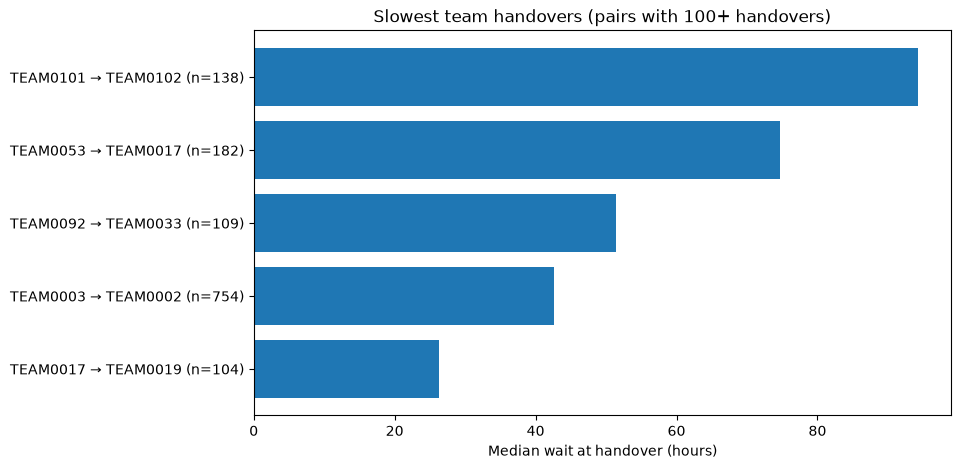

In [15]:
# CELL 14: Chart of the slowest handovers
import matplotlib.pyplot as plt

plot_df = top_handovers.head(5)
labels = [f"{a} → {b} (n={n})" for (a, b), n in zip(plot_df.index, plot_df["count"])]  # n = number of handovers

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(labels[::-1], plot_df["median"].values[::-1])                             # reversed: slowest on top
ax.set_xlabel("Median wait at handover (hours)")
ax.set_title("Slowest team handovers (pairs with 100+ handovers)")
plt.savefig("images/bottlenecks.png", bbox_inches="tight", dpi=150)
plt.show()

**Rework chart:** In this code we plot the median duration per reassignment group, with the ticket count above each bar, and save it for the README and summary slide.

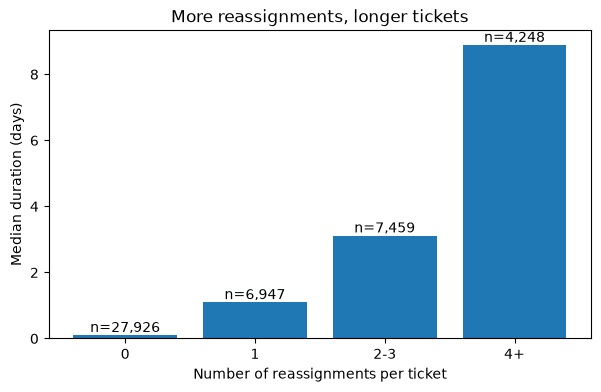

In [16]:
# CELL 15: Chart of rework vs duration
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(rework.index.astype(str), rework["median"])
for i, (n, m) in enumerate(zip(rework["count"], rework["median"])):
    ax.text(i, m, f"n={n:,}", ha="center", va="bottom")                           # ticket count above each bar
ax.set_xlabel("Number of reassignments per ticket")
ax.set_ylabel("Median duration (days)")
ax.set_title("More reassignments, longer tickets")
plt.savefig("images/rework.png", bbox_inches="tight", dpi=150)
plt.show()

In [17]:
# CELL 16: All numbers for README and slide
print("Cases:", case_stats.shape[0])
print("Median duration (days):", round(case_stats["days"].median(), 2))
print("Cases over 30 days:", (case_stats["days"] > 30).sum())
print("Standard-path fit (%):", round(fit["perc_fit_traces"], 1))
print("Discovered-model fit (%):", round(fit_disc["perc_fit_traces"], 1))
print("Slowest handover:", top_handovers.index[0], "median h:", round(top_handovers["median"].iloc[0], 1))
print(rework)

Cases: 46580
Median duration (days): 0.76
Cases over 30 days: 1410
Standard-path fit (%): 59.2
Discovered-model fit (%): 68.1
Slowest handover: ('TEAM0101', 'TEAM0102') median h: 94.3
        count    median  share_%
bucket                          
0       27926  0.096470     60.0
1        6947  1.091690     14.9
2-3      7459  3.110648     16.0
4+       4248  8.882587      9.1


## Key findings
1. **Rework goes hand in hand with delay.** 40% of tickets are reassigned at least once. Tickets with 4+ reassignments (4,248 tickets, 9%) have a median of 8.9 days vs 1.1 days with one reassignment (about 8x) and 0.1 days with none.
2. **The process is highly variable.** Only 44.7% of tickets follow one of the 3 standard paths exactly (59.2% fit the standard model). Even a model learned from all the data fits only 65.8%.
3. **A few handovers stall tickets.** TEAM0101 → TEAM0102 is slowest (median 94 h, n=138). TEAM0003 → TEAM0002 has the largest total impact (754 handovers, median 43 h).

## Recommendation
Add a routing check at the first assignment to reduce reassignments, and escalate tickets waiting more than 24 to 48 hours at a handover, starting with TEAM0003 → TEAM0002 and TEAM0101 → TEAM0102. These are hypotheses to validate with the teams: the data shows where time is lost, not why.

## Limitations
- The standard process is self-defined from the most common paths.
- The 9 core activities were chosen by judgment.
- Waits are calendar hours between core events, not working hours or pure queue time.
- Reassignments and duration influence each other, so this is an association, not proven cause.
- Single company, 2013 to 2014, anonymized teams.